In [ ]:
!pip -q install -U ultralytics torch pyyaml

import glob
import json
import os
import shutil
import zipfile
from pathlib import Path

import torch
import yaml
from google.colab import files
from IPython.display import Image, display
from ultralytics import YOLO


MODELO_YOLO = "yolo26s.pt"
EPOCAS = 50
BATCH_SIZE = 8
IMG_SIZE = 640
CONF_INFERENCIA = 0.35
IOU_INFERENCIA = 0.45

In [ ]:
def carregar_modelo(nome_modelo: str) -> YOLO:
    if nome_modelo.endswith("n.pt"):
        raise ValueError("Versão nano,'yolo26s.pt' ou 'yolo26m.pt'.")
    return YOLO(nome_modelo)


def preparar_dataset_31_fotos(
    zip_path: str,
    extract_dir: str = "/content/raw_dataset",
    out_dir: str = "/content/dataset_31",
):
    shutil.rmtree(extract_dir, ignore_errors=True)
    shutil.rmtree(out_dir, ignore_errors=True)
    os.makedirs(extract_dir, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(extract_dir)

    for split in ["train", "valid"]:
        os.makedirs(os.path.join(out_dir, split, "images"), exist_ok=True)
        os.makedirs(os.path.join(out_dir, split, "labels"), exist_ok=True)

    yaml_files = glob.glob(os.path.join(extract_dir, "**", "data.yaml"), recursive=True)
    coco_files = glob.glob(os.path.join(extract_dir, "**", "*.json"), recursive=True)

    if yaml_files:
        src_yaml = yaml_files[0]
        src_root = os.path.dirname(src_yaml)
        with open(src_yaml, "r", encoding="utf-8") as f:
            cfg = yaml.safe_load(f)

        class_names = cfg.get("names", ["skate-de-dedo"])
        if isinstance(class_names, dict):
            class_names = [class_names[k] for k in sorted(class_names.keys())]

        img_paths = sorted([
            p for p in glob.glob(os.path.join(src_root, "**", "*.*"), recursive=True)
            if Path(p).suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
        ])
        lbl_map = {
            Path(p).stem: p
            for p in glob.glob(os.path.join(src_root, "**", "*.txt"), recursive=True)
            if Path(p).name.lower() != "readme.txt"
        }

        for img_p in img_paths:
            stem = Path(img_p).stem
            ext = Path(img_p).suffix
            for split in ["train", "valid"]:
                shutil.copy2(img_p, os.path.join(out_dir, split, "images", f"{stem}{ext}"))
                lbl_out = os.path.join(out_dir, split, "labels", f"{stem}.txt")
                if stem in lbl_map:
                    shutil.copy2(lbl_map[stem], lbl_out)
                else:
                    Path(lbl_out).write_text("")

    elif coco_files:
        with open(coco_files[0], "r", encoding="utf-8") as f:
            coco = json.load(f)

        cat_map = {c["id"]: c["name"] for c in coco["categories"]}
        used_ids = sorted({a["category_id"] for a in coco["annotations"]})
        id_to_idx = {cid: idx for idx, cid in enumerate(used_ids)}
        class_names = [cat_map[cid] for cid in used_ids]

        anns_by_img = {}
        for ann in coco["annotations"]:
            anns_by_img.setdefault(ann["image_id"], []).append(ann)

        all_imgs = {
            os.path.basename(p): p
            for p in glob.glob(os.path.join(extract_dir, "**", "*.*"), recursive=True)
            if Path(p).suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
        }

        for img_info in coco["images"]:
            fname = os.path.basename(img_info["file_name"])
            src_img = all_imgs.get(fname)
            if not src_img:
                continue

            w_img, h_img = img_info["width"], img_info["height"]
            stem = Path(fname).stem
            linhas = []
            for ann in anns_by_img.get(img_info["id"], []):
                x, y, bw, bh = ann["bbox"]
                xc = (x + bw / 2.0) / w_img
                yc = (y + bh / 2.0) / h_img
                nw = bw / w_img
                nh = bh / h_img
                cls_idx = id_to_idx[ann["category_id"]]
                linhas.append(f"{cls_idx} {xc:.6f} {yc:.6f} {nw:.6f} {nh:.6f}")

            for split in ["train", "valid"]:
                shutil.copy2(src_img, os.path.join(out_dir, split, "images", fname))
                Path(os.path.join(out_dir, split, "labels", f"{stem}.txt")).write_text("\n".join(linhas))
    else:
        raise FileNotFoundError("Não foi encontrado data.yaml nem arquivo JSON COCO no ZIP.")

    out_yaml = os.path.join(out_dir, "data.yaml")
    novo_cfg = {
        "path": out_dir,
        "train": "train/images",
        "val": "valid/images",
        "nc": len(class_names),
        "names": class_names,
    }
    with open(out_yaml, "w", encoding="utf-8") as f:
        yaml.dump(novo_cfg, f, allow_unicode=True)

    qtd_train = len(glob.glob(os.path.join(out_dir, "train", "images", "*.*")))
    qtd_val = len(glob.glob(os.path.join(out_dir, "valid", "images", "*.*")))
    print(f"Dataset pronto | Classes: {class_names}")
    print(f"Imagens em train: {qtd_train} | Imagens em valid: {qtd_val}")
    return out_yaml, novo_cfg


def anexar_reduce_lr_on_plateau(trainer, mode="min", factor=0.5, patience=6, min_lr=1e-6):
    estado = {"scheduler": None}

    def ao_fim_da_epoca(t):
        if not hasattr(t, "optimizer") or t.optimizer is None:
            return
        if estado["scheduler"] is None:
            estado["scheduler"] = torch.optim.lr_scheduler.ReduceLROnPlateau(
                t.optimizer,
                mode=mode,
                factor=factor,
                patience=patience,
                min_lr=min_lr,
            )

        metrics = getattr(t, "metrics", {}) or {}
        val_box = metrics.get("val/box_loss", 0.0)
        val_cls = metrics.get("val/cls_loss", 0.0)
        val_dfl = metrics.get("val/dfl_loss", 0.0)
        perda_val = float(val_box) + float(val_cls) + float(val_dfl)

        lr_antes = t.optimizer.param_groups[0]["lr"]
        estado["scheduler"].step(perda_val)
        lr_depois = t.optimizer.param_groups[0]["lr"]

        if lr_depois < lr_antes:
            print(
                f"\n[ReduceLROnPlateau] LR reduzido: {lr_antes:.2e} -> {lr_depois:.2e} "
                f"(val_loss={perda_val:.4f})"
            )

    trainer.add_callback("on_fit_epoch_end", ao_fim_da_epoca)


zips = glob.glob("/content/*.zip")
if not zips:
    print("Envie o arquivo .zip do Roboflow:")
    uploaded = files.upload()
    zip_path = list(uploaded.keys())[0]
else:
    zip_path = zips[0]
    print(f"Usando ZIP: {zip_path}")

data_yaml, cfg = preparar_dataset_31_fotos(zip_path)

Usando ZIP: /content/Skate-Skate1 - Auto Label.coco.zip
Dataset pronto | Classes: ['skate-de-dedo']
Imagens em train: 30 | Imagens em valid: 30


In [ ]:
modelo = carregar_modelo(MODELO_YOLO)
anexar_reduce_lr_on_plateau(modelo, mode="min", factor=0.5, patience=6, min_lr=1e-6)

resultados = modelo.train(
    data=data_yaml,
    epochs=EPOCAS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    cos_lr=False,
    lr0=1e-3,
    lrf=1.0,
    degrees=20.0,
    scale=0.5,
    hsv_s=0.6,
    hsv_v=0.4,
    plots=True,
    project="/content/runs",
    name=f"treino_{Path(MODELO_YOLO).stem}_31fotos_plateau",
    exist_ok=True,
)

run_dir = str(resultados.save_dir)
best_model = YOLO(os.path.join(run_dir, "weights", "best.pt"))
print("Treinamento finalizado. Pasta:", run_dir)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_31/data.yaml, degrees=20.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.6, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=1.0, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=treino_yolo26s_31fotos_plateau, nbs=64, nms=None, opset=None

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1502.4±348.2 MB/s, size: 70.3 KB)
val: Scanning /content/dataset_31/valid/labels.cache... 30 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 30/30 6.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.1s/it 2.1s
                   all         30         30    0.00333          1     0.0905     0.0772
Speed: 4.6ms preprocess, 9.9ms inference, 0.0ms loss, 4.4ms postprocess per image
Results saved to /content/runs/detect/val-4
Modelo: yolo26s.pt | Imagens usadas: 31 treino / 31 valid
Precision: 0.003 | Recall: 1.000
mAP@50:    0.091 | mAP@50-95: 0.077


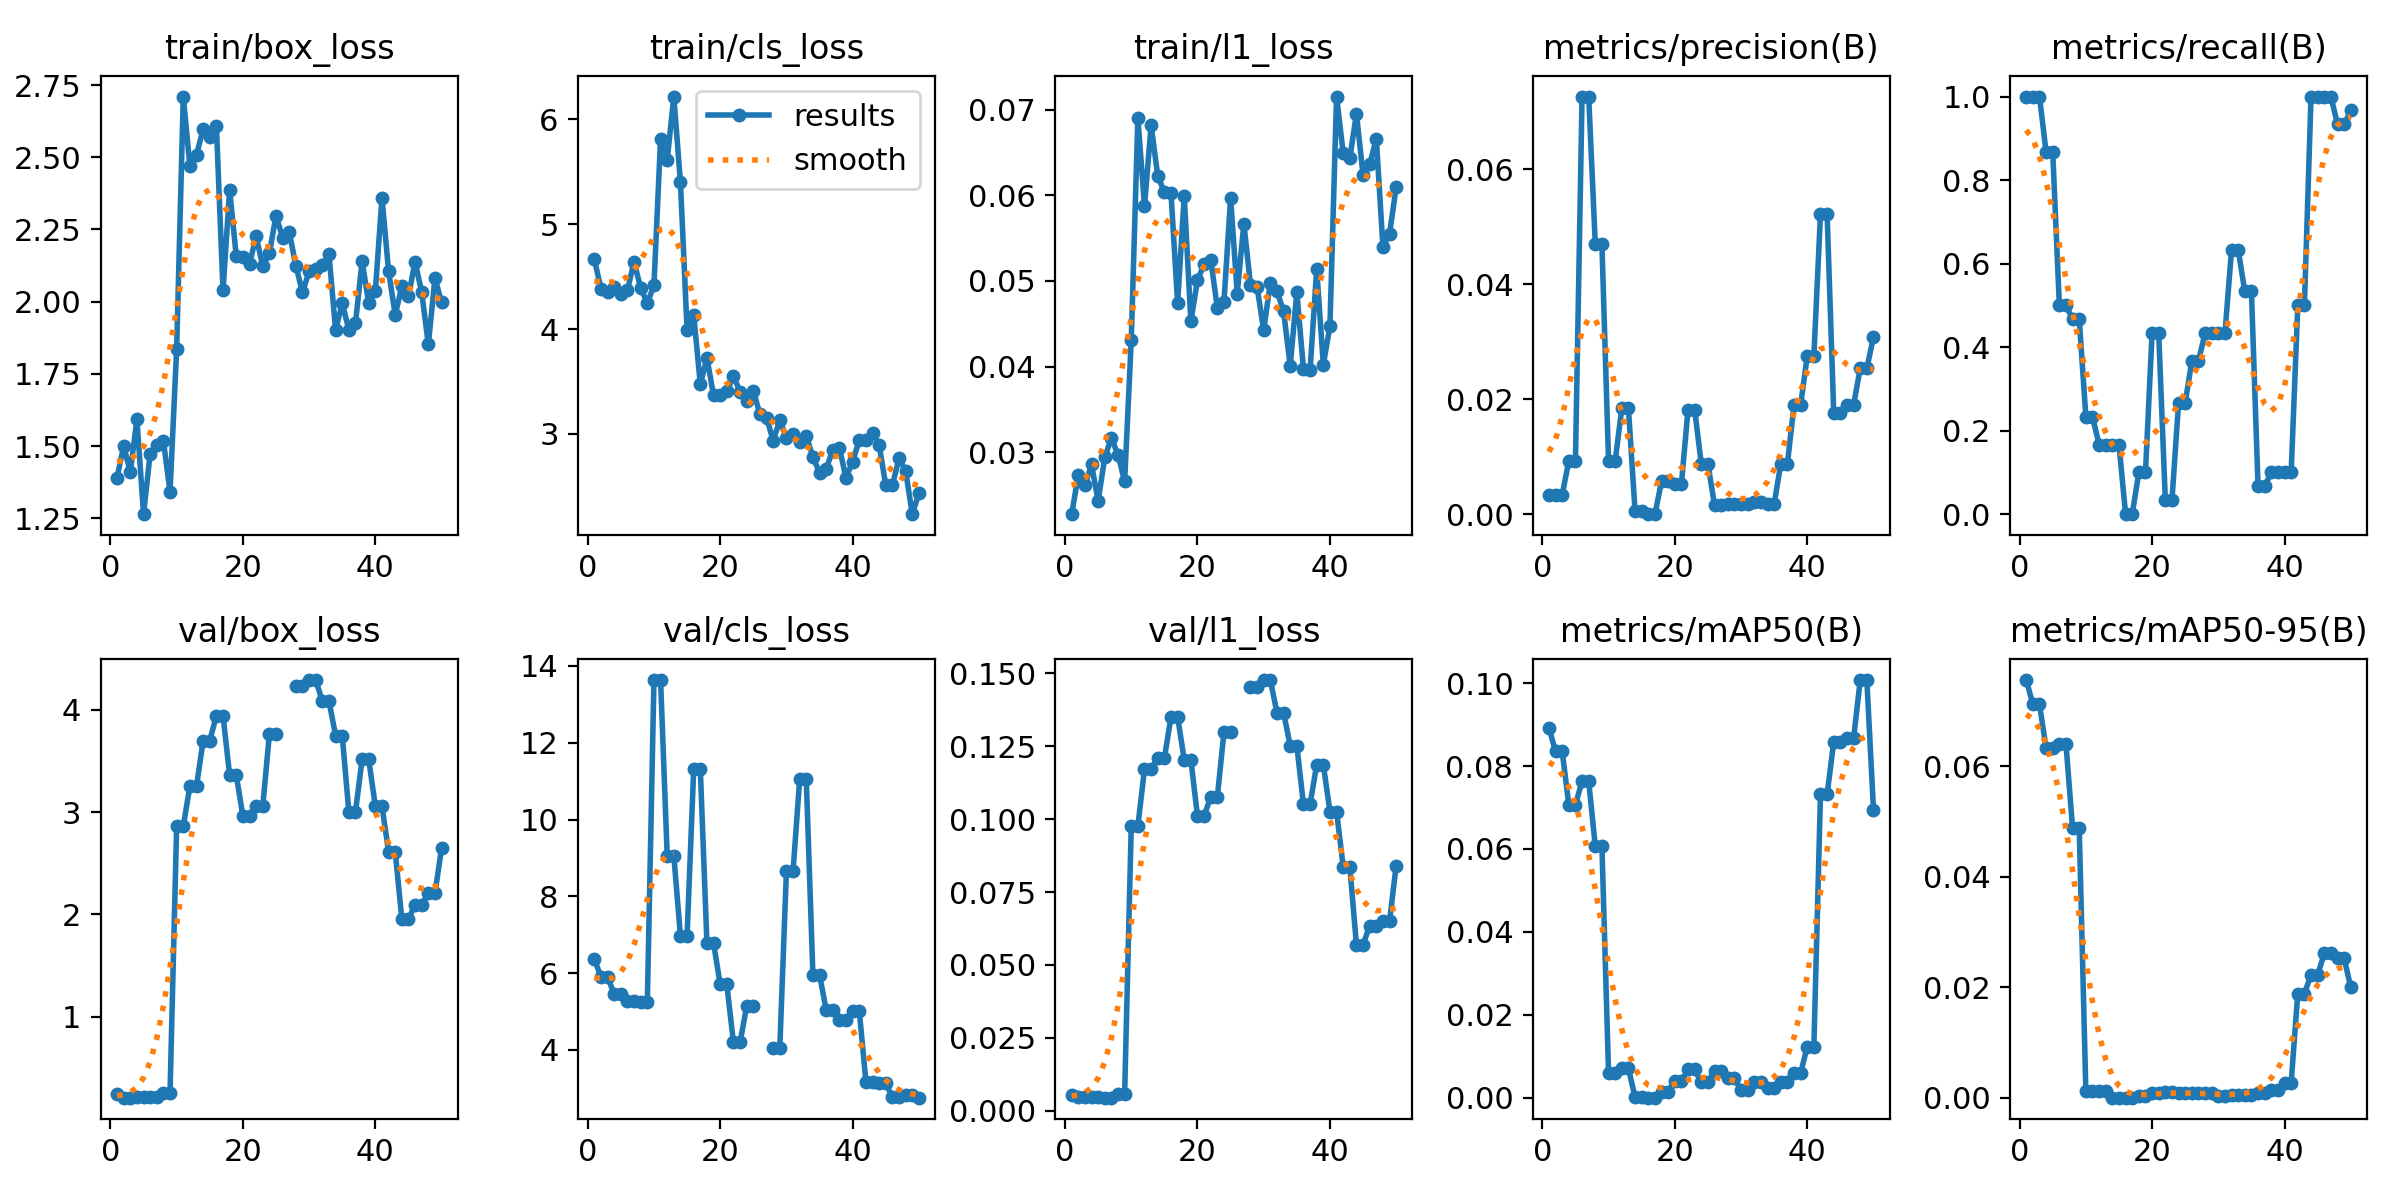

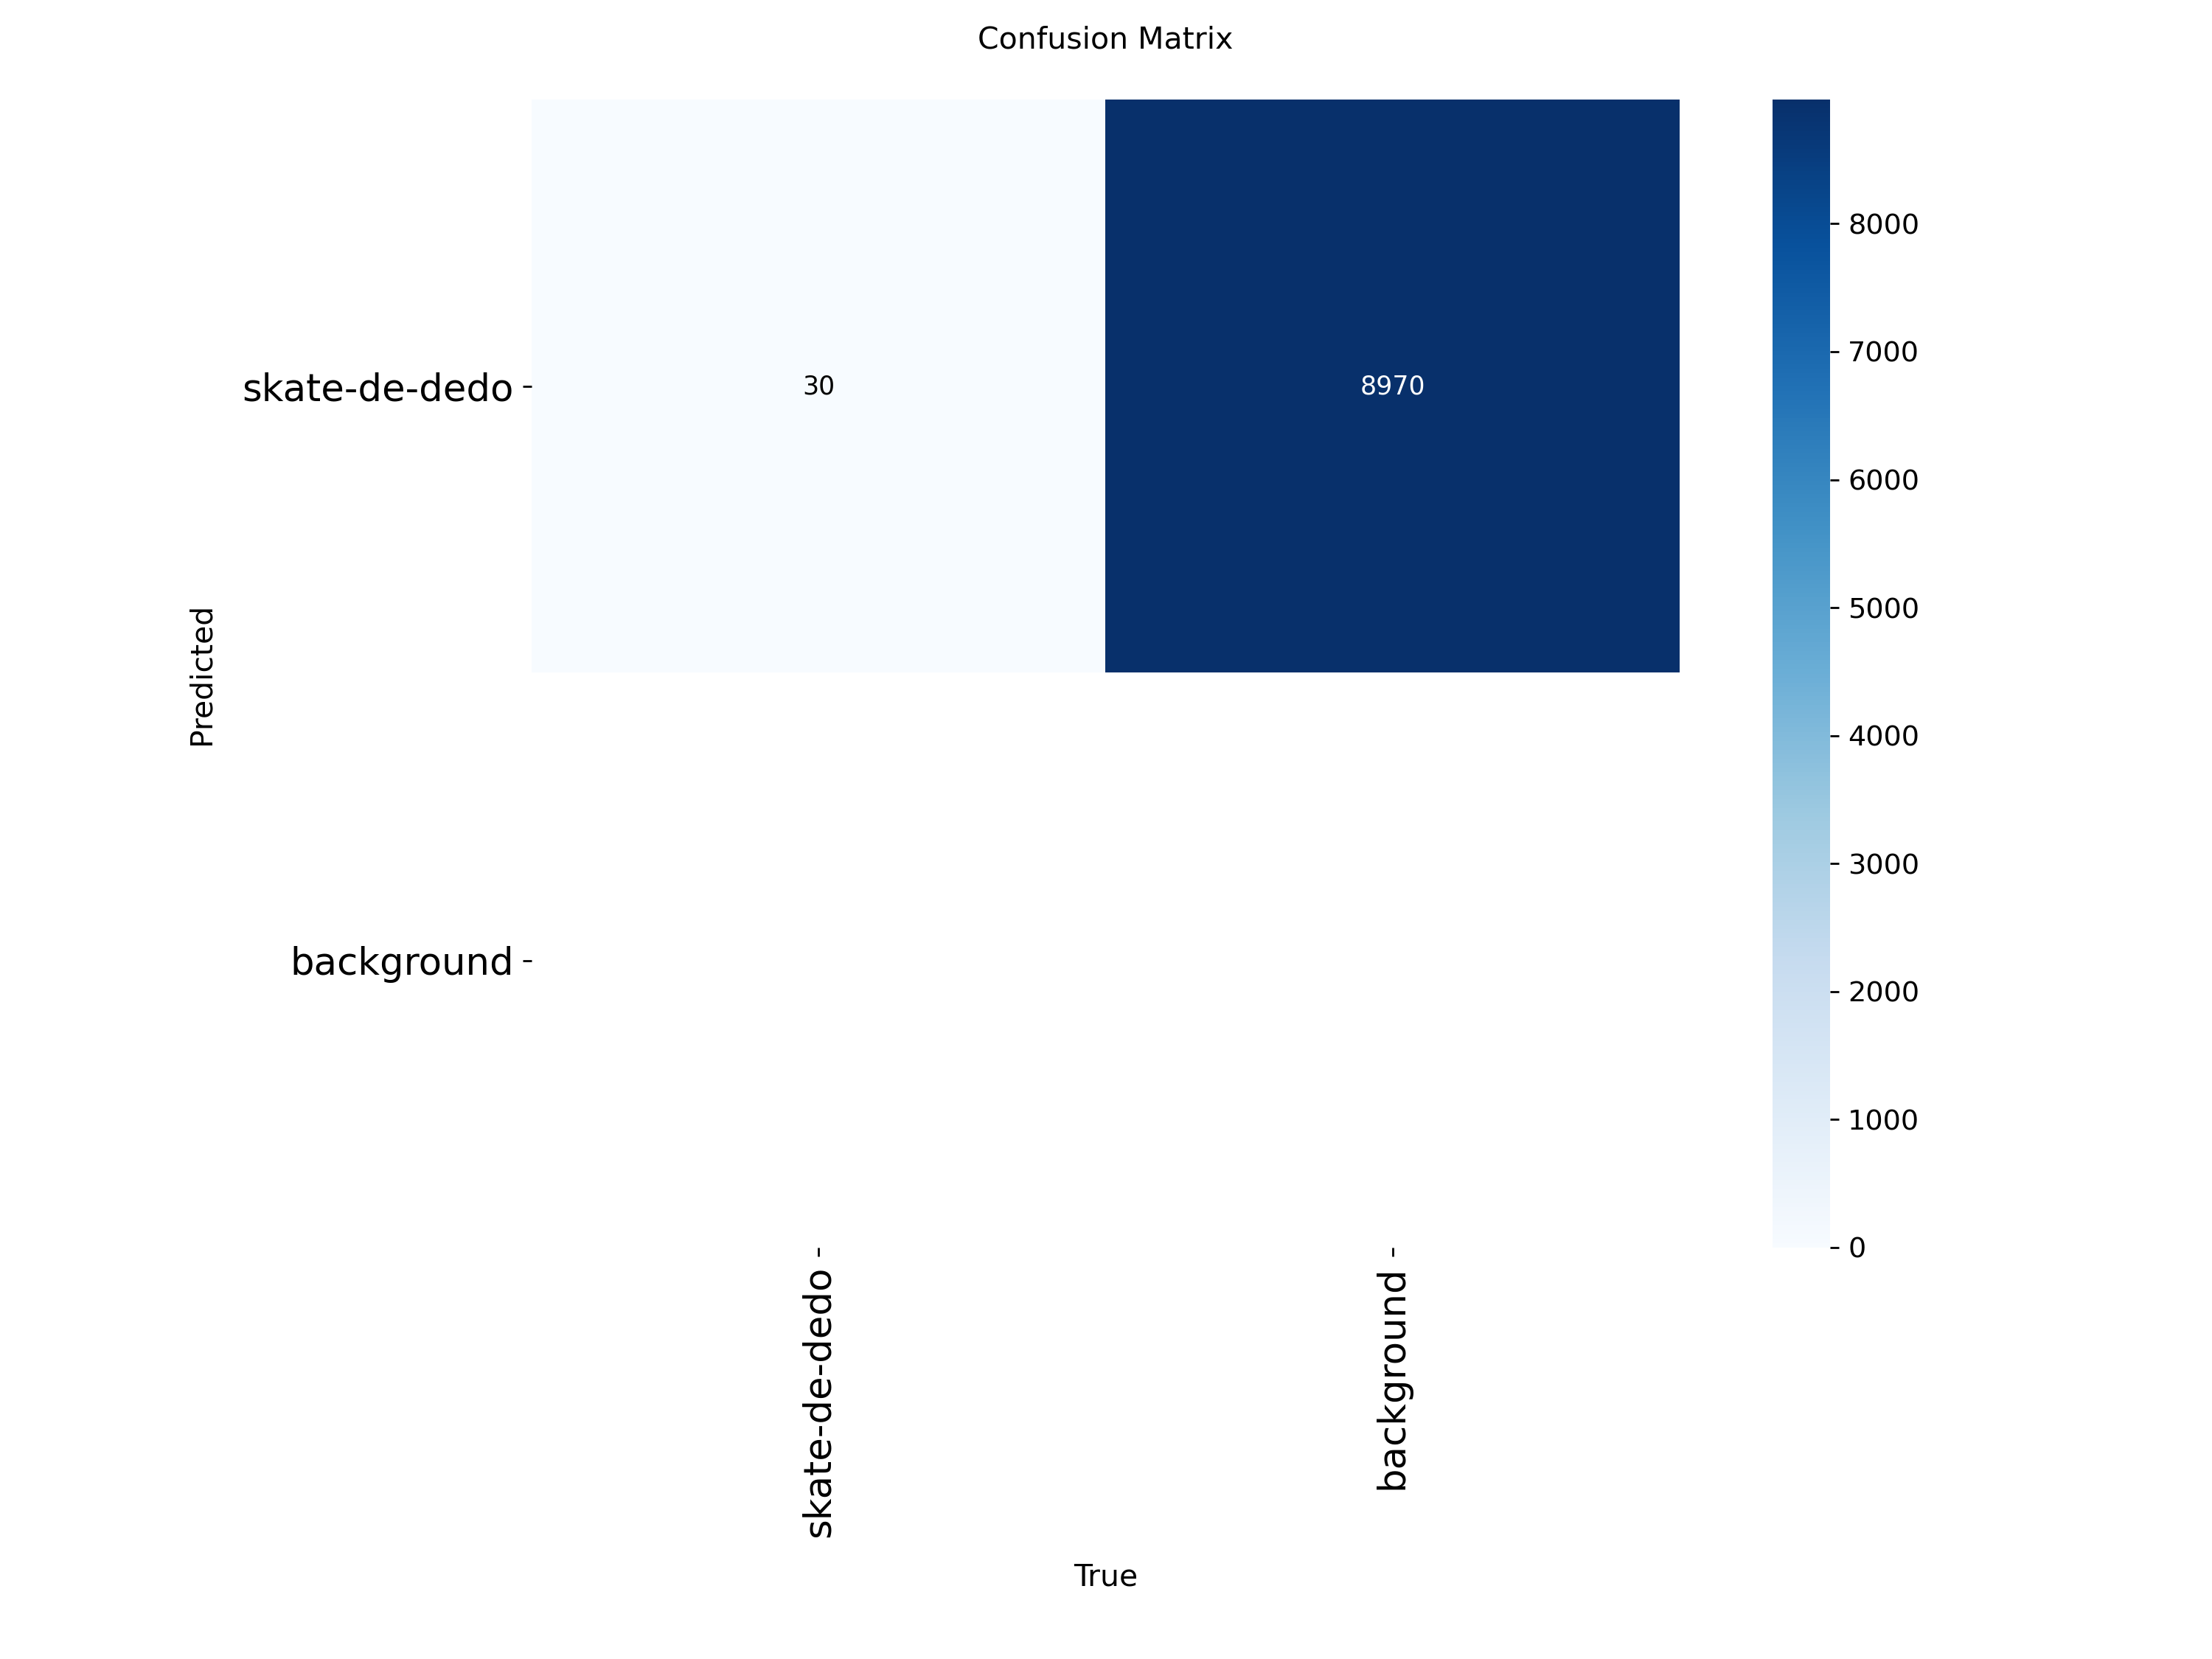

In [ ]:
val_metrics = best_model.val()

print("=" * 55)
print(f"Modelo: {MODELO_YOLO} | Imagens usadas: 31 treino / 31 valid")
print(f"Precision: {val_metrics.box.mp:.3f} | Recall: {val_metrics.box.mr:.3f}")
print(f"mAP@50:    {val_metrics.box.map50:.3f} | mAP@50-95: {val_metrics.box.map:.3f}")
print("=" * 55)

display(Image(filename=os.path.join(run_dir, "results.png"), width=850))
display(Image(filename=os.path.join(run_dir, "confusion_matrix.png"), width=550))

In [ ]:
import glob, os, shutil
from google.colab import files
from ultralytics import YOLO

pesos = sorted(glob.glob("/content/runs/**/weights/best.pt", recursive=True))
best_model = YOLO(pesos[-1])

print("Envie o vídeo de perto (.mp4/.avi):")
up_video = files.upload()
video_path = list(up_video.keys())[0]

shutil.rmtree("/content/runs/inferencia_closeup", ignore_errors=True)

pred = best_model.predict(
    source=video_path,
    conf=0.10,
    iou=0.45,
    max_det=1,
    save=True,
    project="/content/runs",
    name="inferencia_closeup",
    exist_ok=True,
)

confs = [float(r.boxes.conf[0]) for r in pred if len(r.boxes) > 0]
print(f"Frames com detecção: {len(confs)}/{len(pred)} | Confiança máxima: {max(confs) if confs else 0:.3f}")

saida = glob.glob(os.path.join(str(pred[0].save_dir), "*.*"))[0]
files.download(saida)

Envie o vídeo de perto (.mp4/.avi):


Saving WhatsApp Video 2026-11-24 at 23.36.04.mp4 to WhatsApp Video 2026-11-24 at 23.36.04.mp4

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/2287) /content/WhatsApp Video 2026-11-24 at 23.36.04.mp4: 640x384 1 skate-de-dedo, 12.0ms
video 1/1 (frame 2/2287) /content/WhatsApp Video 2026-11-24 at 23.36.04.mp4: 640x384 1 skate-de-dedo, 14.1ms
video 1/1 (frame 3/2287) /content/WhatsApp Video 2026-11-24 at 23.36.04.mp4: 640x384 1 skate-de-dedo, 15.4ms
video 1/1 (frame 4/2287) /content/What

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Selecione o vídeo (.mp4/.avi) para fazer upload:


Saving WhatsApp Video 2026-11-24 at 23.16.48.mp4 to WhatsApp Video 2026-11-24 at 23.16.48.mp4

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/710) /content/WhatsApp Video 2026-11-24 at 23.16.48.mp4: 640x384 (no detections), 11.6ms
video 1/1 (frame 2/710) /content/WhatsApp Video 2026-11-24 at 23.16.48.mp4: 640x384 (no detections), 11.6ms
video 1/1 (frame 3/710) /content/WhatsApp Video 2026-11-24 at 23.16.48.mp4: 640x384 (no detections), 11.6ms
video 1/1 (frame 4/710) /content/WhatsApp

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>